# Two-way time transfer between two boards (27–28 October 2026)

Boards **8873292600AB** (node A, 192.168.2.100) and **887329260072A** (node B, 192.168.2.99), RF-clock 1.3.0.10 on both, run `20261028_001010`: 600 s of two-way time transfer (TWTT) with both boards on one FS725, i.e. a **zero-baseline** measurement: the true clock offset is 0, so the θ measured here is the system's own constant (non-reciprocity) plus its noise.

The method, the equations and the correlation are explained in `TWTT_selftest_Oct_27.ipynb` (one board through its own loopback, the same evening). This notebook uses the same analysis for two boards.

**Contents**
1. Set-up and commands
2. The data: one second worked through by hand
3. Completeness and signal quality
4. The two one-way measurements
5. The clock offset θ
6. The one-way delay
7. Stability with averaging (standard deviation of the mean, Allan deviation)
8. The saved captures: the two directions side by side
9. Diagnosis: why the BA direction is weak and wanders
10. Comparison with the one-board self-test and with the two-board test of 21 October
11. Summary

## 1. Set-up and commands

| | Node A: 8873292600AB | Node B: 887329260072A |
|---|---|---|
| Role | listens for B; transmits in slot AB (PPS + 100 ms), receives in slot BA (PPS + 600 ms) | connects to A; receives in slot AB, transmits in slot BA |
| 10 MHz | EPG1 REF OUT → resistive splitter → external reference | the same splitter, other port |
| PPS | FS725 1PPS → EPG1 → **output 1** (0.52 ns actual delay) → J7 | → **output 2** (7.48 ns actual delay) → J7; the two PPS cables differ slightly |
| RF out | DAC_A → band-pass filter → attenuator → **B's ADC_B** (direction AB) | DAC_A → band-pass filter → attenuator → **A's ADC_B** (direction BA) |
| RF-clock | 1.3.0.10 (upgraded from 1.3.0.8 the same evening; MTS capture codes re-recorded, M2 PASS) | 1.3.0.10 |
| VCO bands (ADC/DAC) | 124 / 126 | 118 / 122 |
| MTS latencies | DAC 1944, ADC 1296 | DAC 1944, ADC 1296 |
| NTP | RF-clock-PC (192.168.2.1), synchronized | the same |

Before the run, M1 on both boards with this wiring (60 s each): every PPS period exactly 100 000 000 ticks, jitter 0, `pps_locked`.

On each board (`~/jupyter_notebooks/felipe/rf_clock/logs/`), A started 3 s before B:
```
sudo env BOARD=RFSoC4x2 XILINX_XRT=/usr /usr/local/share/pynq-venv/bin/python -u -m rf_clock.twtt.node A \
     --seconds 600 --log twtt_A_20261028_001010.jsonl --save-every 60 --save-dir rx_A_20261028_001010
sudo env ... -m rf_clock.twtt.node B --peer 192.168.2.100 \
     --seconds 600 --log twtt_B_20261028_001010.jsonl --save-every 60 --save-dir rx_B_20261028_001010
```
Each board logs its own records (`local`), the other board's (`peer`, sent over the network) and the paired `result` (θ and delay) of every second; both compute the same results. `--save-every 60` keeps each board's received windows once a minute (`rx_*/<slot>_<PPS count>.npy`). Everything is copied to `rf_clock_board/twtt_pair/20261028_001010/`.

**With both boards on one FS725 the true offset is 0**, so

$$\theta_{\text{measured}} = \frac{m_{AB} - m_{BA}}{2} = \frac{\Delta}{2} + \text{(difference of the two boards' PPS-to-tick timing)}$$

a constant of the set-up (the zero-baseline calibration value), and its scatter is the precision of the system.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Defining my usual plot appearance settings

In [2]:
plt.rcParams['font.size'] = '20';plt.rcParams['font.style'] = 'normal'
plt.rcParams['font.weight'] = 'normal';plt.rcParams['axes.grid'] = True;plt.rcParams['grid.linestyle'] = '-';
plt.rcParams['grid.linewidth'] = 0.4;plt.rcParams['grid.color'] = "Black";plt.rcParams['grid.alpha'] = 1;
plt.rcParams['lines.linewidth'] = 3;#plt.rcParams['axes.autolimit_mode'] = 'round_numbers';plt.rcParams['axes.axisbelow'] = True
plt.rcParams['xtick.direction'] = 'in';plt.rcParams['ytick.direction'] = 'in';plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.width'] = 0.5;plt.rcParams['ytick.major.width'] = 1;plt.rcParams['ytick.minor.width'] = 0.5;
plt.rcParams['xtick.major.size'] = 4;plt.rcParams['xtick.minor.size'] = 2;plt.rcParams['ytick.major.size'] = 4;
plt.rcParams['ytick.minor.size'] = 2; plt.rcParams['svg.fonttype'] = 'none'; #cs = list(mcolors.TABLEAU_COLORS.values())
plt.rcParams['axes.linewidth']=1;plt.rcParams['xtick.top'] = True;plt.rcParams['ytick.right'] = True;
plt.rcParams['axes.spines.top'] = True;plt.rcParams['axes.spines.bottom'] = True;plt.rcParams['axes.spines.left'] = True;
plt.rcParams['axes.spines.right'] = True# Plot Appearance Settings

In [3]:
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.width'] = 1.5;plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1;plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 7;plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 3.5;plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams['xtick.minor.visible'] = True;plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['axes.axisbelow'] = True

def grids(ax):
    ax.grid(which='major', color='Black', linewidth=0.6, alpha=1)
    ax.grid(which='minor', color='Black', linewidth=0.3, alpha=0.35)

## 2. The data

In [4]:
RUN = "20261028_001010"
DIR = Path("rf_clock_board/twtt_pair") / RUN
FIG = DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def read(path):
    return [json.loads(l) for l in open(path)]

logA, logB = read(DIR / f"twtt_A_{RUN}.jsonl"), read(DIR / f"twtt_B_{RUN}.jsonl")
infoA = next(l for l in logA if l["type"] == "info"); infoB = next(l for l in logB if l["type"] == "info")
locA = [l for l in logA if l["type"] == "local"]; locB = [l for l in logB if l["type"] == "local"]
resA = [l for l in logA if l["type"] == "result"]; resB = [l for l in logB if l["type"] == "result"]
for name, info, loc, res, log in (("A", infoA, locA, resA, logA), ("B", infoB, locB, resB, logB)):
    ev = [e["event"] for e in log if e["type"] == "event"]
    print(f"node {name}: {info['label']}, rf-clock {info['rf_clock']}, bands {info['bands']}: "
          f"{len(loc)} own seconds, {len(res)} paired results, events {ev}")
same = all(abs(a["theta_ns"] - b["theta_ns"]) < 1e-9 for a, b in zip(resA, resB))
print(f"both boards computed the same theta for every paired second: {same}")

t0 = resA[0]["t_sys"]
t = np.array([r["t_sys"] - t0 for r in resA])
m_ab = np.array([r["m_ab_ns"] for r in resA]); m_ba = np.array([r["m_ba_ns"] for r in resA])
theta = np.array([r["theta_ns"] for r in resA]); delay = np.array([r["delay_ns"] for r in resA])
byA = {l["count"]: l for l in locA}; byB = {l["count"]: l for l in locB}
rxA = [byA[r["count_a"]]["slots"]["BA"]["rx"] for r in resA]     # A receives in slot BA
rxB = [byB[r["count_b"]]["slots"]["AB"]["rx"] for r in resA]     # B receives in slot AB
psl_ab = np.array([x["psl_db"] for x in rxB]); psl_ba = np.array([x["psl_db"] for x in rxA])
ph_ab = np.array([x["phase"] for x in rxB]); ph_ba = np.array([x["phase"] for x in rxA])

node A: 8873292600AB, rf-clock 1.3.0.10, bands {'adc': 124, 'dac': 126}: 600 own seconds, 593 paired results, events ['accepted 192.168.2.99']
node B: 887329260072A, rf-clock 1.3.0.10, bands {'adc': 118, 'dac': 122}: 600 own seconds, 593 paired results, events ['connected to 192.168.2.100:50725', 'disconnected: closed by the other board']
both boards computed the same theta for every paired second: True


### One second worked through by hand

$m_{AB}$ uses A's transmit tick and B's receive window, each counted from its own board's PPS tick; $m_{BA}$ the other way round:

$$m = \big[(\text{RX\_ACTUAL} - \text{PPS}_{\text{receiver}}) - (\text{TX\_ACTUAL} - \text{PPS}_{\text{transmitter}})\big] \times 10\ \text{ns} + \text{peak} \times 1.25\ \text{ns}$$

In [5]:
r = resA[10]; a, b = byA[r["count_a"]], byB[r["count_b"]]
for s, tx_rec, rx_rec, logged in (("AB", a, b, r["m_ab_ns"]), ("BA", b, a, r["m_ba_ns"])):
    tx = tx_rec["slots"][s]["tx"] - tx_rec["pps_tick"]
    rx = rx_rec["slots"][s]["rx"]["tick"] - rx_rec["pps_tick"]
    peak = rx_rec["slots"][s]["rx"]["peak"]
    m = (rx - tx) * 10 + peak * 1.25
    print(f"slot {s}: {tx_rec['node']} TX at PPS+{tx} ticks, {rx_rec['node']} window at PPS+{rx} ticks, peak {peak:.4f} samples")
    print(f"         m_{s} = ({rx} - {tx}) x 10 ns + {peak:.4f} x 1.25 ns = {m:.4f} ns   (logged {logged:.4f} ns)")
print(f"theta = (m_AB - m_BA)/2 = {(r['m_ab_ns'] - r['m_ba_ns']) / 2 * 1e3:+.2f} ps; "
      f"one-way delay = (m_AB + m_BA)/2 = {r['delay_ns']:.4f} ns")
print(f"(PPS counts differ, A {r['count_a']} / B {r['count_b']}: each board counts from its own start; "
      f"the seconds are paired by their NTP time)")

slot AB: A TX at PPS+10000000 ticks, B window at PPS+9999875 ticks, peak 1233.5245 samples
         m_AB = (9999875 - 10000000) x 10 ns + 1233.5245 x 1.25 ns = 291.9056 ns   (logged 291.9056 ns)
slot BA: B TX at PPS+60000000 ticks, A window at PPS+59999875 ticks, peak 1234.5386 samples
         m_BA = (59999875 - 60000000) x 10 ns + 1234.5386 x 1.25 ns = 293.1733 ns   (logged 293.1733 ns)
theta = (m_AB - m_BA)/2 = -633.81 ps; one-way delay = (m_AB + m_BA)/2 = 292.5394 ns
(PPS counts differ, A 23 / B 16: each board counts from its own start; the seconds are paired by their NTP time)


## 3. Completeness and signal quality

paired seconds: 593 (A ran 600 s, B 600 s; B started 3 s after A and ended 3 s after it)
valid: 593, slot errors: 0
AB (A -> B): PSL min 22.0, mean 22.1 dB; carrier phase -2.741 rad, sd 38 mrad
BA (B -> A): PSL min 21.7, mean 22.0 dB; carrier phase -1.006 rad, sd 74 mrad
die temperature: A 40.7-43.5 C, B 51.5-54.2 C


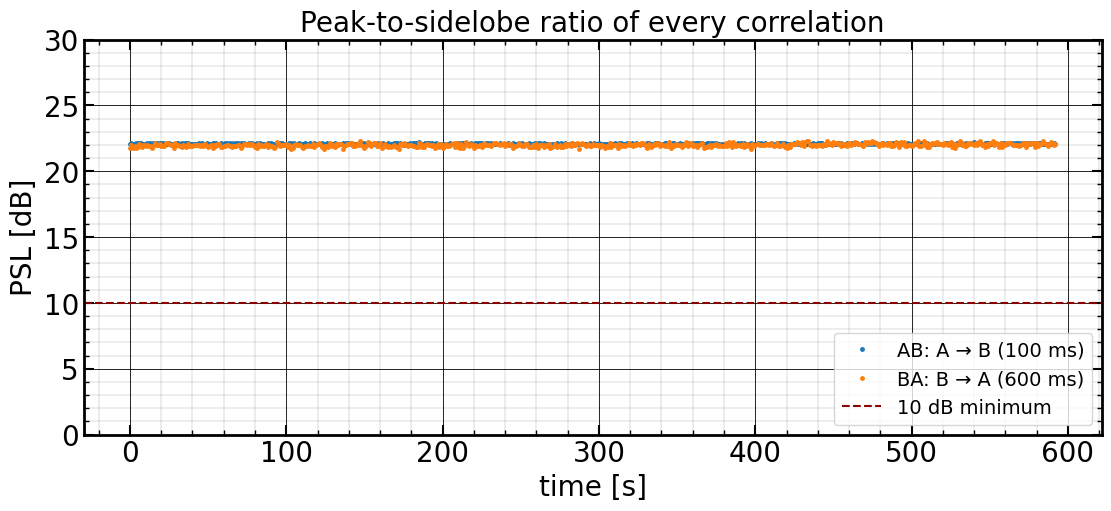

In [6]:
print(f"paired seconds: {len(resA)} (A ran {len(locA)} s, B {len(locB)} s; B started 3 s after A and ended 3 s after it)")
print(f"valid: {np.isfinite(theta).sum()}, slot errors: "
      f"{sum('error' in l['slots'][s] for l in locA + locB for s in l['slots'])}")
for name, p, ph in (("AB (A -> B)", psl_ab, ph_ab), ("BA (B -> A)", psl_ba, ph_ba)):
    print(f"{name}: PSL min {p.min():.1f}, mean {p.mean():.1f} dB; carrier phase {ph.mean():+.3f} rad, sd {ph.std(ddof=1) * 1e3:.0f} mrad")
dieA = np.array([l["die_c"] for l in locA]); dieB = np.array([l["die_c"] for l in locB])
print(f"die temperature: A {dieA.min():.1f}-{dieA.max():.1f} C, B {dieB.min():.1f}-{dieB.max():.1f} C")

fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(t, psl_ab, ".", ms=5, color="tab:blue", label="AB: A → B (100 ms)")
ax.plot(t, psl_ba, ".", ms=5, color="tab:orange", label="BA: B → A (600 ms)")
ax.axhline(10, color="darkred", ls="--", lw=1.5, label="10 dB minimum")
ax.set_ylim(0, 30); ax.set_xlabel("time [s]"); ax.set_ylabel("PSL [dB]")
ax.set_title("Peak-to-sidelobe ratio of every correlation", fontsize=20)
ax.legend(fontsize=14, loc="lower right"); grids(ax)
fig.savefig(FIG / "psl.png", dpi=150); plt.show()

## 4. The two one-way measurements

Each direction as a deviation from its own mean. The directions are different hardware (AB: A's DAC, the AB cable, B's ADC; BA: B's DAC, the BA cable, A's ADC), so their means differ by the non-reciprocity.

m_AB: mean 291.9071 ns, sdev  1.88 ps, second-to-second 1.93 ps, trend -0.03 ps/min, range 11.6 ps
m_BA: mean 293.2015 ns, sdev 15.79 ps, second-to-second 5.79 ps, trend +4.82 ps/min, range 74.8 ps
correlation between m_AB and m_BA of the same second: -0.05


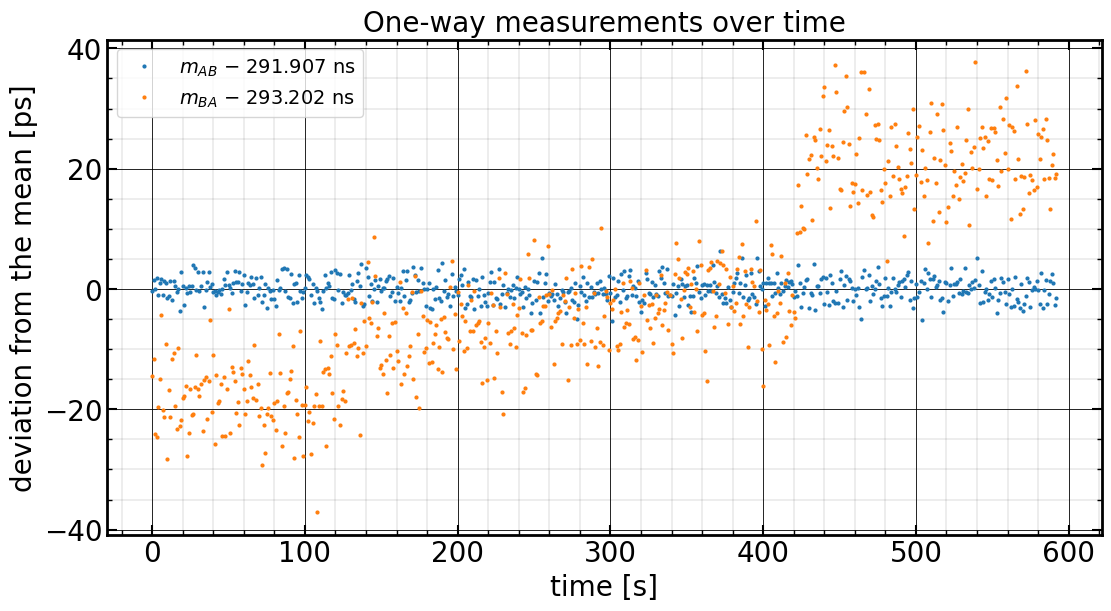

In [7]:
def trend(x):
    return np.polyfit(t, x, 1)[0] * 60
for name, m in (("m_AB", m_ab), ("m_BA", m_ba)):
    print(f"{name}: mean {m.mean():.4f} ns, sdev {m.std(ddof=1) * 1e3:5.2f} ps, "
          f"second-to-second {np.diff(m).std(ddof=1) / np.sqrt(2) * 1e3:4.2f} ps, "
          f"trend {trend(m) * 1e3:+.2f} ps/min, range {np.ptp(m) * 1e3:.1f} ps")
print(f"correlation between m_AB and m_BA of the same second: {np.corrcoef(m_ab, m_ba)[0, 1]:+.2f}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - m_ab.mean()) * 1e3, ".", ms=4, color="tab:blue", label=f"$m_{{AB}}$ − {m_ab.mean():.3f} ns")
ax.plot(t, (m_ba - m_ba.mean()) * 1e3, ".", ms=4, color="tab:orange", label=f"$m_{{BA}}$ − {m_ba.mean():.3f} ns")
ax.set_xlabel("time [s]"); ax.set_ylabel("deviation from the mean [ps]")
ax.set_title("One-way measurements over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "one_way.png", dpi=150); plt.show()

## 5. The clock offset θ

$\theta = (m_{AB} - m_{BA})/2$, the zero-baseline constant. Shown over time with a 30-s running mean, then per minute, then as a histogram.

theta: mean -0.64724 ns (-647.2 ps), sdev 8.00 ps, second-to-second 3.09 ps, range 38.9 ps


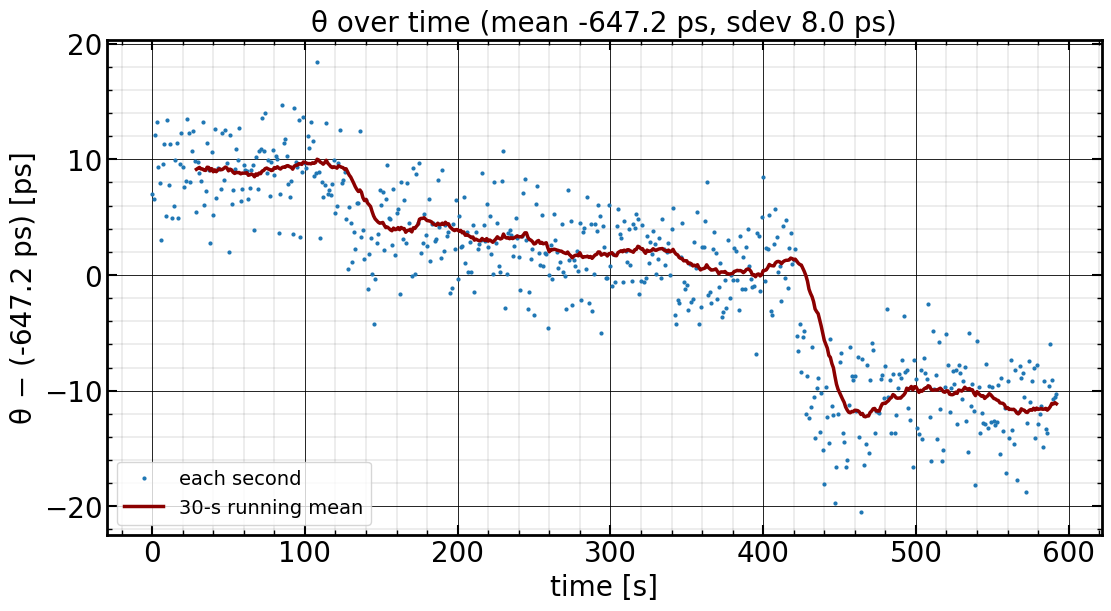

per minute:
    0- 60 s: theta   +8.98 ps (sdev 2.85), m_AB  +0.48, m_BA -17.47 ps
   60-120 s: theta   +9.41 ps (sdev 2.96), m_AB  +0.02, m_BA -18.79 ps
  120-180 s: theta   +4.65 ps (sdev 3.42), m_AB  +0.35, m_BA  -8.95 ps
  180-240 s: theta   +3.31 ps (sdev 2.75), m_AB  -0.30, m_BA  -6.91 ps
  240-300 s: theta   +1.90 ps (sdev 3.20), m_AB  -0.64, m_BA  -4.44 ps
  300-360 s: theta   +1.30 ps (sdev 2.69), m_AB  -0.13, m_BA  -2.73 ps
  360-420 s: theta   +0.94 ps (sdev 3.02), m_AB  +0.43, m_BA  -1.46 ps
  420-480 s: theta  -10.48 ps (sdev 4.46), m_AB  -0.08, m_BA +20.87 ps
  480-540 s: theta  -10.03 ps (sdev 3.41), m_AB  +0.26, m_BA +20.32 ps
  540-600 s: theta  -11.29 ps (sdev 2.90), m_AB  -0.43, m_BA +22.16 ps


In [8]:
th_ps = theta * 1e3
th_mean, th_sd = th_ps.mean(), th_ps.std(ddof=1)
print(f"theta: mean {theta.mean():+.5f} ns ({th_mean:+.1f} ps), sdev {th_sd:.2f} ps, "
      f"second-to-second {np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f} ps, range {np.ptp(th_ps):.1f} ps")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, th_ps - th_mean, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve(th_ps - th_mean, np.ones(30) / 30, mode="valid"), "-", color="darkred", lw=2.5,
        label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"θ − ({th_mean:+.1f} ps) [ps]")
ax.set_title(f"θ over time (mean {th_mean:+.1f} ps, sdev {th_sd:.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "theta_time.png", dpi=150); plt.show()

print("per minute:")
for k in range(0, len(th_ps), 60):
    s = slice(k, k + 60)
    print(f"  {k:3d}-{k + 60:3d} s: theta {th_ps[s].mean() - th_mean:+7.2f} ps (sdev {th_ps[s].std(ddof=1):4.2f}), "
          f"m_AB {(m_ab[s].mean() - m_ab.mean()) * 1e3:+6.2f}, m_BA {(m_ba[s].mean() - m_ba.mean()) * 1e3:+6.2f} ps")

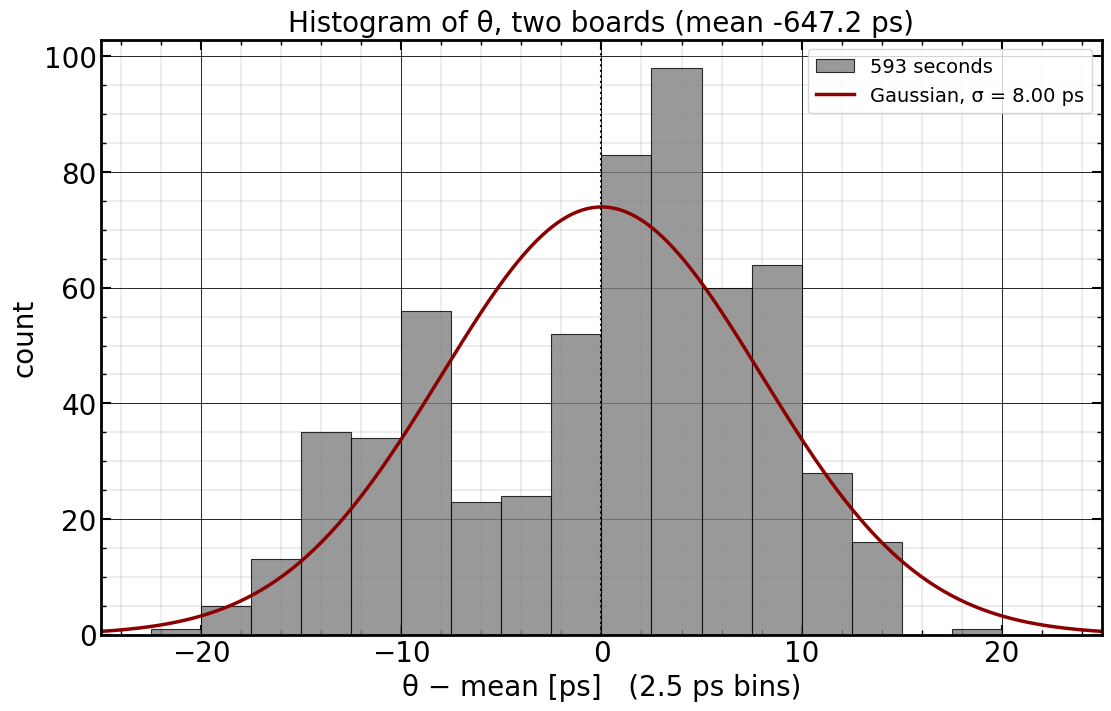

Shapiro-Wilk p = 1.2e-11 (not Gaussian: the distribution is the noise plus the slow wander and the step)


In [9]:
BIN_PS = 2.5
dev = th_ps - th_mean
edge = BIN_PS * np.ceil(np.abs(dev).max() / BIN_PS + 1)
bins = np.arange(-edge, edge + BIN_PS / 2, BIN_PS)
x = np.linspace(bins[0], bins[-1], 400)
fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(dev, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{dev.size} seconds")
ax.plot(x, dev.size * BIN_PS * stats.norm.pdf(x, 0, th_sd), "-", color="darkred", lw=2.5,
        label=f"Gaussian, σ = {th_sd:.2f} ps")
ax.axvline(0, color="k", ls=":", lw=1.5)
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ − mean [ps]   ({BIN_PS} ps bins)"); ax.set_ylabel("count")
ax.set_title(f"Histogram of θ, two boards (mean {th_mean:+.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "theta_histogram.png", dpi=150); plt.show()
print(f"Shapiro-Wilk p = {stats.shapiro(dev).pvalue:.1e} (not Gaussian: the distribution is the noise plus the slow wander and the step)")

## 6. The one-way delay

$(m_{AB} + m_{BA})/2$: cables, filters, attenuators and both boards' converter paths.

one-way delay: mean 292.5543 ns, sdev 7.91 ps, trend +2.39 ps/min


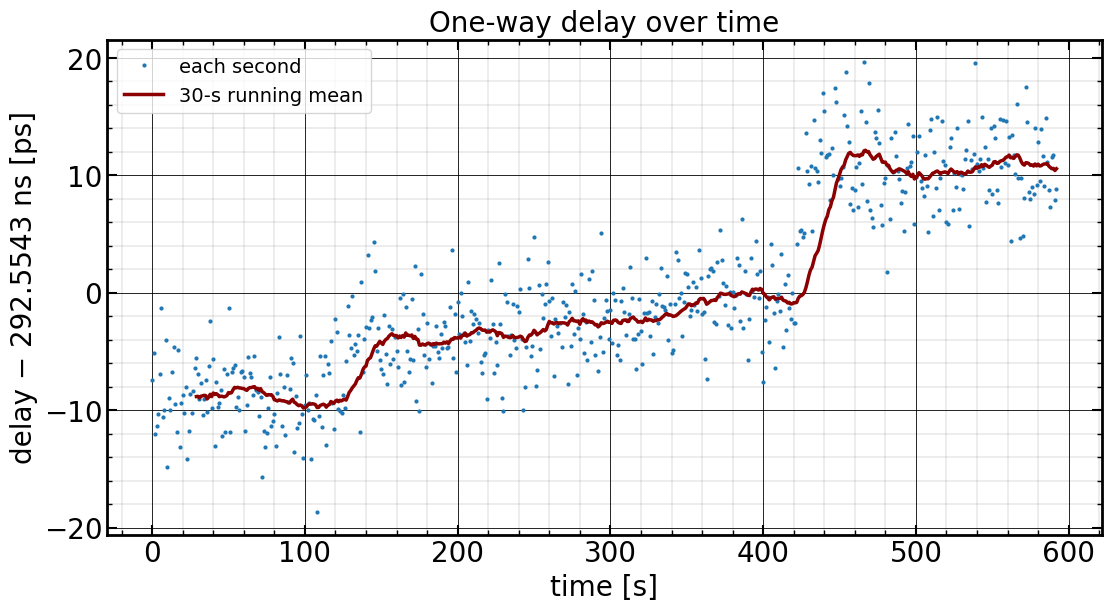

In [10]:
print(f"one-way delay: mean {delay.mean():.4f} ns, sdev {delay.std(ddof=1) * 1e3:.2f} ps, trend {trend(delay) * 1e3:+.2f} ps/min")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (delay - delay.mean()) * 1e3, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve((delay - delay.mean()) * 1e3, np.ones(30) / 30, mode="valid"), "-", color="darkred",
        lw=2.5, label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"delay − {delay.mean():.4f} ns [ps]")
ax.set_title("One-way delay over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "delay_time.png", dpi=150); plt.show()

## 7. Stability with averaging

Standard deviation of the mean of N consecutive seconds, and the overlapping Allan deviation of θ (θ taken as the time error between the two boards; see the self-test notebook for the definition).

N =   1: theta  8.00   m_AB  1.88   m_BA 15.79 ps
N =   2: theta  7.68   m_AB  1.35   m_BA 15.22 ps
N =   5: theta  7.50   m_AB  0.84   m_BA 14.89 ps
N =  10: theta  7.47   m_AB  0.57   m_BA 14.85 ps
N =  20: theta  7.39   m_AB  0.45   m_BA 14.69 ps
N =  30: theta  7.34   m_AB  0.38   m_BA 14.61 ps
N =  60: theta  7.13   m_AB  0.37   m_BA 14.24 ps


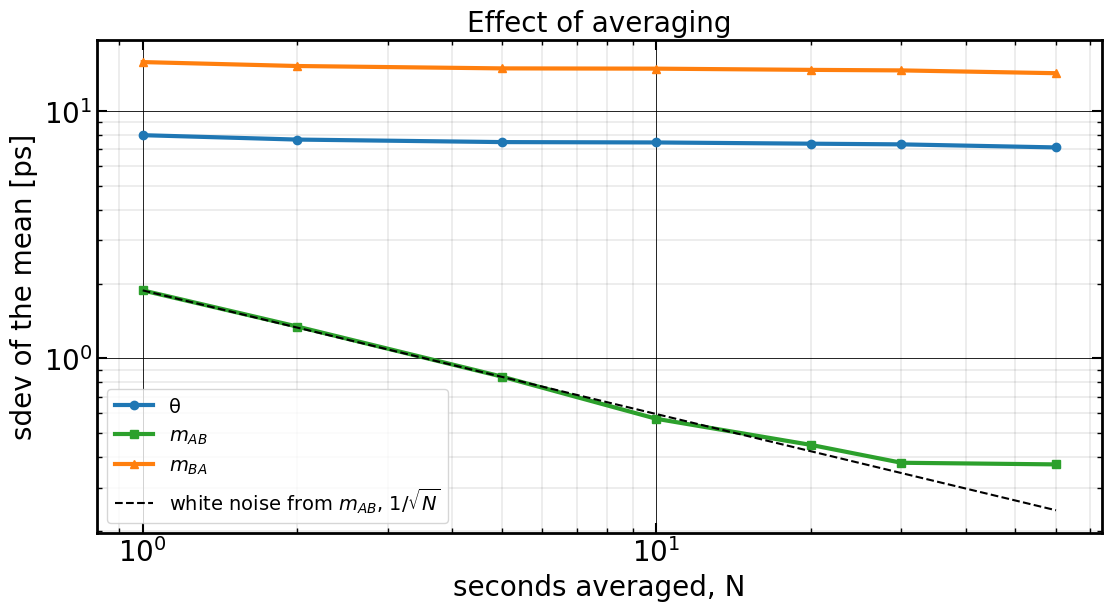

In [11]:
def sd_of_mean(y, Ns):
    out = []
    for n in Ns:
        k = y.size // n
        out.append(y[: k * n].reshape(k, n).mean(axis=1).std(ddof=1))
    return np.array(out)

def oadev(x_s, taus):
    return np.array([np.sqrt(np.mean((x_s[2 * m:] - 2 * x_s[m:-m] + x_s[:-2 * m]) ** 2) / (2 * m ** 2)) for m in taus])

Ns = np.array([1, 2, 5, 10, 20, 30, 60])
sd_th, sd_ab, sd_ba = sd_of_mean(th_ps, Ns), sd_of_mean(m_ab * 1e3, Ns), sd_of_mean(m_ba * 1e3, Ns)
for n, a, b, c in zip(Ns, sd_th, sd_ab, sd_ba):
    print(f"N = {n:3d}: theta {a:5.2f}   m_AB {b:5.2f}   m_BA {c:5.2f} ps")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(Ns, sd_th, "o-", color="tab:blue", label="θ")
ax.loglog(Ns, sd_ab, "s-", color="tab:green", label="$m_{AB}$")
ax.loglog(Ns, sd_ba, "^-", color="tab:orange", label="$m_{BA}$")
ax.loglog(Ns, sd_ab[0] / np.sqrt(Ns), "k--", lw=1.5, label="white noise from $m_{AB}$, $1/\\sqrt{N}$")
ax.set_xlabel("seconds averaged, N"); ax.set_ylabel("sdev of the mean [ps]")
ax.set_title("Effect of averaging", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "averaging.png", dpi=150); plt.show()

tau =   1 s: ADEV 5.33e-12
tau =   2 s: ADEV 2.68e-12
tau =   3 s: ADEV 1.79e-12
tau =   4 s: ADEV 1.41e-12
tau =   7 s: ADEV 8.08e-13
tau =  11 s: ADEV 4.93e-13
tau =  18 s: ADEV 3.22e-13
tau =  29 s: ADEV 2.13e-13
tau =  47 s: ADEV 1.48e-13
tau =  75 s: ADEV 9.33e-14
tau = 122 s: ADEV 6.31e-14
tau = 197 s: ADEV 3.40e-14


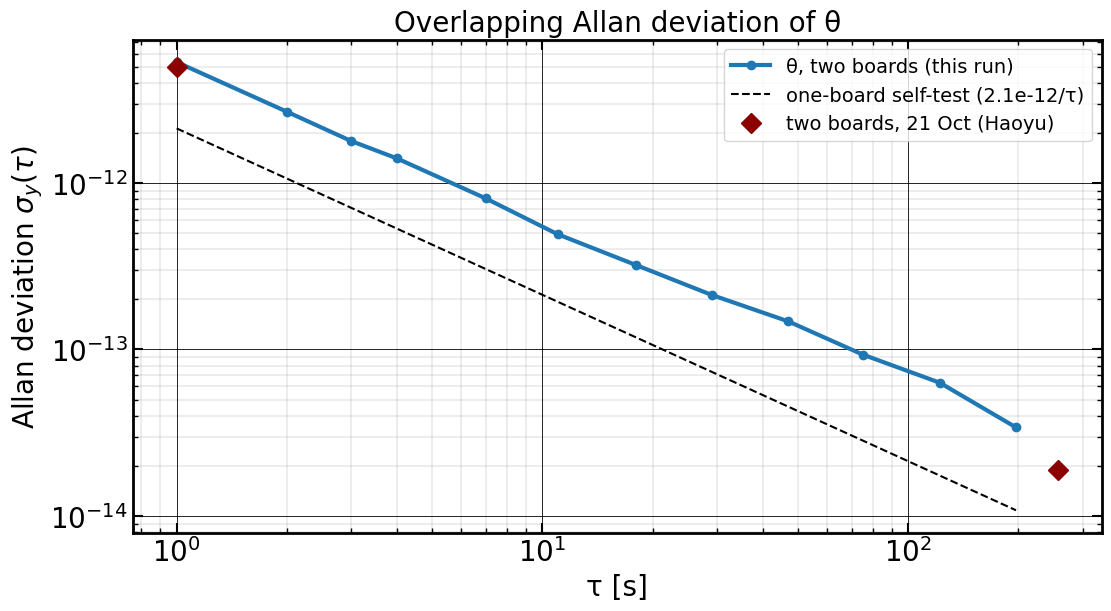

In [12]:
taus = np.unique(np.round(np.logspace(0, np.log10(th_ps.size // 3), 12)).astype(int))
ad = oadev(th_ps * 1e-12, taus)
for tau, v in zip(taus, ad):
    print(f"tau = {tau:3d} s: ADEV {v:.2e}")
ad_self = 2.13e-12 / taus                    # one-board self-test: 2.13e-12 at 1 s, falling as 1/tau
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", label="θ, two boards (this run)")
ax.loglog(taus, ad_self, "k--", lw=1.5, label="one-board self-test (2.1e-12/τ)")
ax.loglog([1, 256], [5.0e-12, 1.9e-14], "D", color="darkred", ms=10, label="two boards, 21 Oct (Haoyu)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Overlapping Allan deviation of θ", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "allan.png", dpi=150); plt.show()

## 8. The saved captures: the two directions side by side

Every 60 s each board kept the window it received (A: slot BA, B: slot AB). The PRN reference is the same waveform and amplitude as in M3 (taken from the M3 capture file), and the correlator is the RF-clock source in this repository.

In [13]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location(
    "correlator", "rf_clock_board/reference/rf_clock_v1.3.0.8/src/rf_clock/correlator.py")
correlator = importlib.util.module_from_spec(spec); sys.modules["correlator"] = correlator
spec.loader.exec_module(correlator)
ref = np.load("rf_clock_board/logs/m3_capture_20261027_232357.npz")["ref"]

def saved(rx_dir, slot):
    files = sorted(rx_dir.glob(f"{slot}_*.npy"), key=lambda p: int(p.stem.split("_")[1]))
    return [(int(f.stem.split("_")[1]), np.load(f).astype(np.complex128)) for f in files]

capAB = saved(DIR / f"rx_B_{RUN}", "AB"); capBA = saved(DIR / f"rx_A_{RUN}", "BA")
print("count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL")
for (ca, xa), (cb, xb) in zip(capAB, capBA):
    pa, pb = correlator.estimate_delay(xa, ref), correlator.estimate_delay(xb, ref)
    print(f"{ca:4d}/{cb:<4d}        {np.sqrt(np.mean(np.abs(xa) ** 2)):6.1f} {pa.index:8.3f} {pa.peak_to_sidelobe_db:5.1f}  |"
          f"        {np.sqrt(np.mean(np.abs(xb) ** 2)):6.1f} {pb.index:8.3f} {pb.peak_to_sidelobe_db:5.1f}")
lvl_ab = np.median([np.sqrt(np.mean(np.abs(x) ** 2)) for _, x in capAB[1:]])
lvl_ba = np.median([np.sqrt(np.mean(np.abs(x) ** 2)) for _, x in capBA[1:]])
print(f"\nreceived level, BA relative to AB: {20 * np.log10(lvl_ba / lvl_ab):+.1f} dB "
      f"(first saved second left out: A's window then came before B had started)")

count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL
   6/6            103.4 1233.525  22.1  |           8.8 9196.766   0.0
  66/66           103.4 1233.528  22.1  |          29.6 1234.550  21.7
 126/126          103.4 1233.528  22.0  |          29.4 1234.551  21.9
 186/186          103.4 1233.526  22.1  |          29.0 1234.547  22.0
 246/246          103.4 1233.526  22.1  |          29.5 1234.555  22.2
 306/306          103.4 1233.525  22.1  |          29.5 1234.554  22.1
 366/366          103.4 1233.526  22.1  |          29.7 1234.562  21.8
 426/426          103.4 1233.525  22.1  |          28.7 1234.554  22.0
 486/486          103.4 1233.527  22.1  |          28.3 1234.583  22.2
 546/546          103.4 1233.530  22.2  |          28.2 1234.581  22.0

received level, BA relative to AB: -10.9 dB (first saved second left out: A's window then came before B had started)


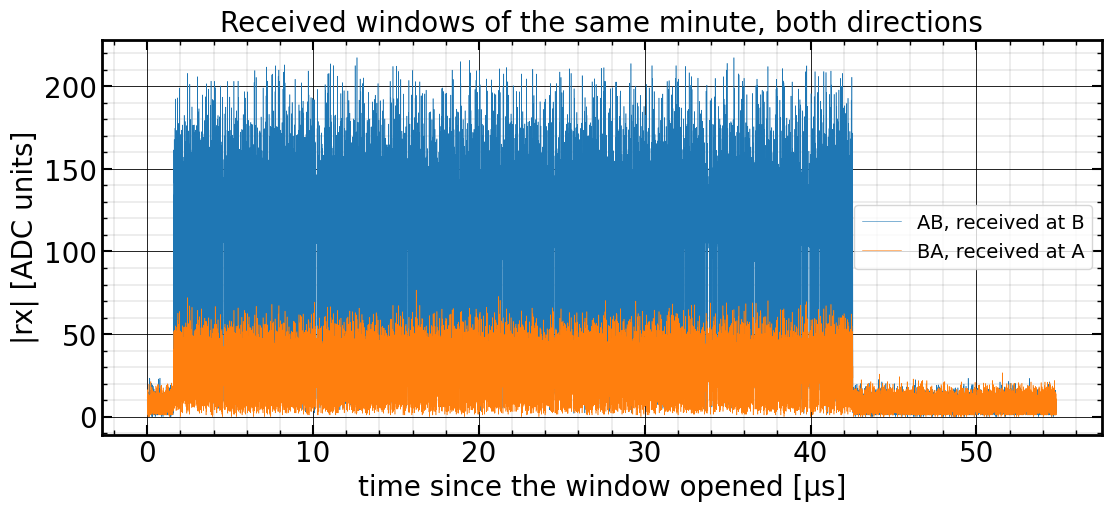

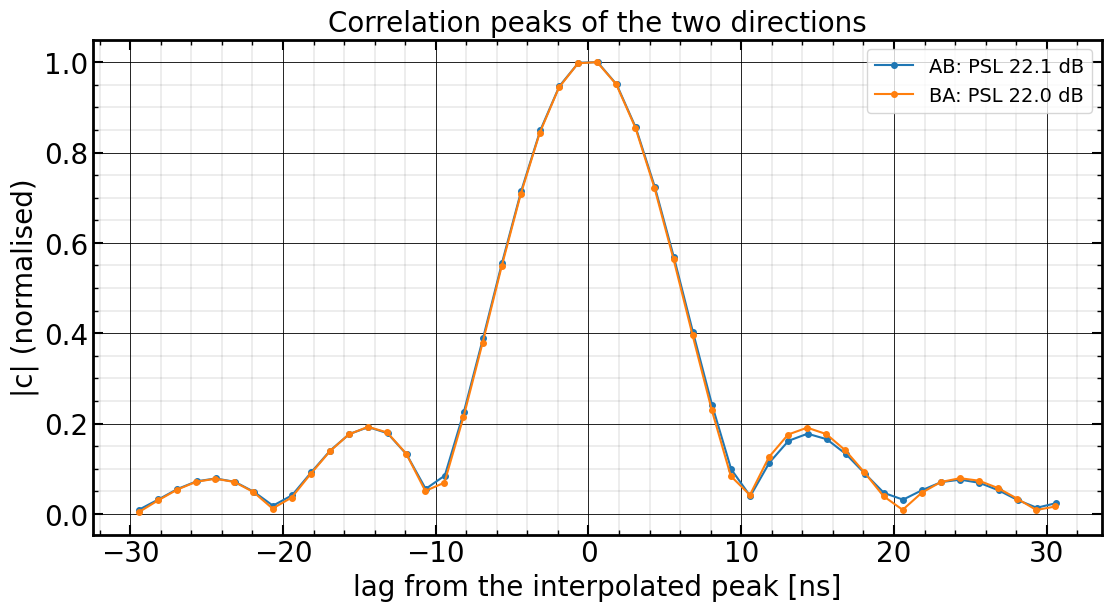

In [14]:
(_, xa), (_, xb) = capAB[3], capBA[3]
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
tt = np.arange(xa.size) / 800e6 * 1e6
ax.plot(tt, np.abs(xa), lw=0.4, color="tab:blue", label="AB, received at B")
ax.plot(tt, np.abs(xb), lw=0.4, color="tab:orange", label="BA, received at A")
ax.set_xlabel("time since the window opened [µs]"); ax.set_ylabel("|rx| [ADC units]")
ax.set_title("Received windows of the same minute, both directions", fontsize=20)
ax.legend(fontsize=14, loc="center right"); grids(ax)
fig.savefig(FIG / "captures.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
for (lab, x, col) in (("AB", xa, "tab:blue"), ("BA", xb, "tab:orange")):
    c = np.abs(correlator.correlate(x, ref)); p = correlator.find_peak(correlator.correlate(x, ref))
    k = p.integer_index; w = np.arange(k - 24, k + 25)
    ax.plot((w - p.index) * 1.25, c[w] / c[k], "o-", ms=4, lw=1.5, color=col, label=f"{lab}: PSL {p.peak_to_sidelobe_db:.1f} dB")
ax.set_xlabel("lag from the interpolated peak [ns]"); ax.set_ylabel("|c| (normalised)")
ax.set_title("Correlation peaks of the two directions", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "correlation_peaks.png", dpi=150); plt.show()

## 9. Diagnosis: the BA direction

Two checks separate a real change of the path from a measurement problem:

* **Signal level.** At the same signal, the correlation noise scales as 1/amplitude, so the per-second noise of each direction should scale with its received level.
* **Group delay against carrier phase.** If the BA path really became longer by δ, the carrier phase measured at A would rotate by −2π × 5.8 GHz × δ (−1.46 rad for 40 ps). If the delay moves while the phase stays, the path length did not change.

per-second noise BA/AB: 2.99;  amplitude AB/BA: 3.52


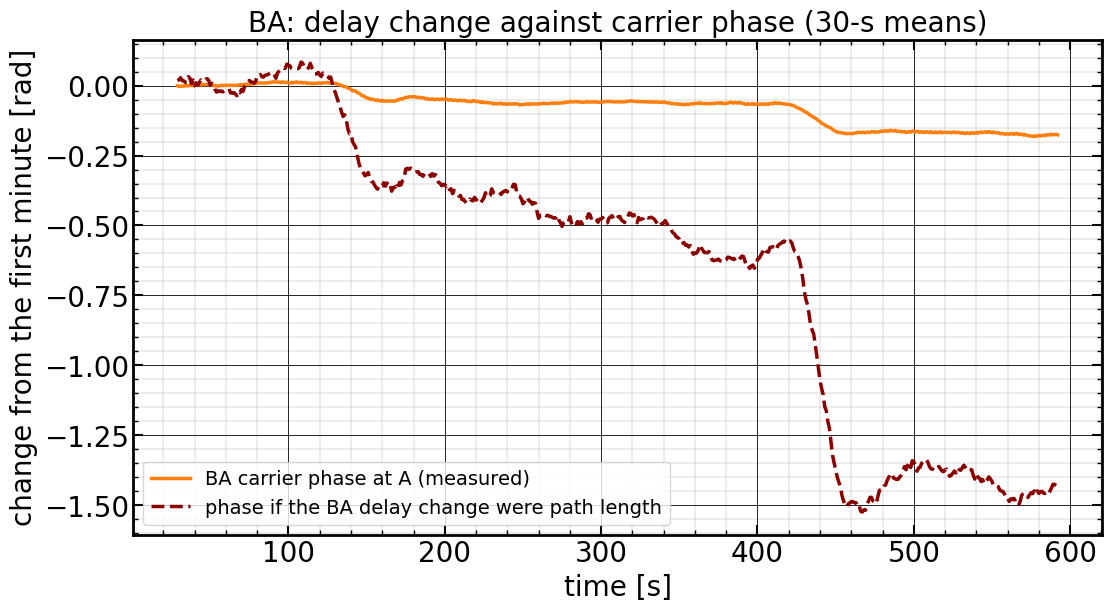

largest 20-s change of m_BA: +18.3 ps at t = 448 s; BA phase over the run -0.18 rad (a path change of +39 ps would give -1.43 rad)


In [15]:
noise_ab = np.diff(m_ab).std(ddof=1) / np.sqrt(2) * 1e3
noise_ba = np.diff(m_ba).std(ddof=1) / np.sqrt(2) * 1e3
print(f"per-second noise BA/AB: {noise_ba / noise_ab:.2f};  amplitude AB/BA: {lvl_ab / lvl_ba:.2f}")

win = 30
sm = lambda y: np.convolve(y, np.ones(win) / win, mode="valid")
d_ba_ps = sm((m_ba - m_ba[:60].mean()) * 1e3)
d_ph = sm(np.unwrap(ph_ba) - np.unwrap(ph_ba)[:60].mean())
expected = -2 * np.pi * 5.8e9 * d_ba_ps * 1e-12
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t[win - 1:], d_ph, "-", color="tab:orange", lw=2.5, label="BA carrier phase at A (measured)")
ax.plot(t[win - 1:], expected, "--", color="darkred", lw=2.5, label="phase if the BA delay change were path length")
ax.set_xlabel("time [s]"); ax.set_ylabel("change from the first minute [rad]")
ax.set_title(f"BA: delay change against carrier phase ({win}-s means)", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "ba_phase_vs_delay.png", dpi=150); plt.show()
j = np.argmax(np.abs(d_ba_ps[20:] - d_ba_ps[:-20])) + 20
print(f"largest 20-s change of m_BA: {d_ba_ps[j] - d_ba_ps[j - 20]:+.1f} ps at t = {t[j + win - 1]:.0f} s; "
      f"BA phase over the run {d_ph[-1]:+.2f} rad (a path change of {d_ba_ps[-1]:+.0f} ps would give {expected[-1]:+.2f} rad)")

## 10. Comparison

In [16]:
rows = [
    ("One board (AB), loopback, 27 Oct, 300 s", "0 (truth)", "+0.06", "1.18", "2.1e-12"),
    ("Two boards, this run, 600 s", "0 (one FS725)", f"{th_mean:+.1f}", f"{th_sd:.2f}", f"{ad[0]:.1e}"),
    ("  same, second-to-second only", "", "", f"{np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f}", ""),
    ("Two boards (Haoyu: 072A + 0101), 21 Oct, 600 s", "0 (one FS725)", "+9877.8", "2.95", "5.0e-12"),
]
print(f"{'':48s} {'true θ':>14s} {'θ mean [ps]':>12s} {'sdev [ps]':>10s} {'ADEV 1 s':>9s}")
for r in rows:
    print(f"{r[0]:48s} {r[1]:>14s} {r[2]:>12s} {r[3]:>10s} {r[4]:>9s}")

                                                         true θ  θ mean [ps]  sdev [ps]  ADEV 1 s
One board (AB), loopback, 27 Oct, 300 s               0 (truth)        +0.06       1.18   2.1e-12
Two boards, this run, 600 s                       0 (one FS725)       -647.2       8.00   5.3e-12
  same, second-to-second only                                                      3.09          
Two boards (Haoyu: 072A + 0101), 21 Oct, 600 s    0 (one FS725)      +9877.8       2.95   5.0e-12


## 11. Summary

**The two-board link works end to end.** Both boards ran 600 s on RF-clock 1.3.0.10; 593 seconds were paired (the other 7 are the 3 s by which B started and ended later than A), every one valid, with no slot errors, PSL ≥ 21.7 dB in both directions, and both boards computed identical results. Recomputing one second by hand from the two boards' ticks and peaks gives exactly the logged $m_{AB}$, $m_{BA}$ and θ.

**θ (zero-baseline constant) = −647.2 ps**, standard deviation **8.0 ps** over the 10 minutes. The constant is the non-reciprocity Δ/2 plus the difference of the two boards' PPS-to-tick timing; it is the calibration value of this set-up, not an error. The **second-to-second** scatter is **3.1 ps** and the **Allan deviation 5.3e-12 at 1 s**, the same as Haoyu's two-board result of 21 October (2.95 ps, 5.0e-12). Over longer times θ is dominated by one direction:

* **AB (A → B) is clean:** 1.9 ps per second, flat over the 10 minutes (trend −0.03 ps/min), averaging down to 0.4 ps.
* **BA (B → A) is not:** it arrives **10.9 dB weaker** than AB (received rms 29 against 103 ADC units), its per-second noise is 3× higher (5.8 ps; the amplitude ratio is 3.5, so the extra noise is explained by the lower signal), and its delay **steps by about +15 ps at t ≈ 130 s and +22 ps at t ≈ 425 s** (75 ps range in all) while its carrier phase changed by only −0.18 rad. A real 39 ps change of the path length would have turned the phase by −1.43 rad, so **the BA path did not get longer**: the delay estimate moved without the signal moving. That is what a weak signal with a changing reflection or leak does (for example a loose or worn SMA connector, or a damaged cable or attenuator in the BA path), and the low level points the same way.

The two steps were at about 20:12 and 20:17 (EDT), while the lab was being left: movement on the bench is a possible trigger.

**What to check on the BA path** (hardware, in the lab):
1. The attenuator values of both paths (AB and BA should be equal) and the filter models.
2. Every SMA in the BA path (072A's DAC_A, filter, attenuator, AB's ADC_B): finger-tight or with a torque wrench, cables not under strain.
3. To locate it: swap the BA path's filter, attenuator and cable with the AB path's. If the weak level follows the component, it is the component; if it stays with the direction, it is 072A's DAC_A output (or AB's ADC_B input).
4. Then repeat this run, and once more after both boards are powered up again: θ must come back to the same constant.

**Not yet done:** PPS capture margin of both boards on their EPG1 outputs (needs Haoyu: it restarts the EPG1), and the zero-baseline repeatability across power-ups.

Files: logs, console output and saved captures in `rf_clock_board/twtt_pair/20261028_001010/`, figures in its `figures/` folder.
